In [83]:
from IPython.display import Markdown, display

def printmd(string):
    display(Markdown(string))
print("\n\n\n\n", end="")

# Business Case: Scaler – Clustering (End-to-End Solution)
### - By Shaik Mayeenuddin

In [91]:
print("\n\n\n\n", end="")

## Setingup & Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [89]:
print("\n\n\n\n", end="")

# 1. Problem Statement and Exploratory Data Analysis

## Problem Definition
Scaler wants to profile the best companies and job positions for its learners. By understanding learner salaries, experience, and company tiering, Scaler can tailor its curriculum, manage learner salary expectations, and build strategic partnerships with high-paying companies. We will use manual heuristic clustering (Tier, Class, Designation) and unsupervised machine learning (K-Means, Hierarchical) to uncover these segments

In [136]:
print("\n\n\n\n", end="")

### 1.1 Data Loading & Initial Inspection

In [2]:
# Loading the datasets
df = pd.read_csv('scaler_hashed_for_students.csv')
mapping = pd.read_csv('scaler_job_positions_mapping VX.csv')

# Basic inspection done
print(f"Dataset Shape: {df.shape}")
display(df.head())

# Dropping unnamed index column if exists
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

print("\nDataset Info:")
df.info()

Dataset Shape: (205843, 7)


,Unnamed: 0,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year
0,0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.0,1100000,Other,2020.0
1,1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.0,449999,FullStack Engineer,2019.0
2,2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000,Backend Engineer,2020.0
3,3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.0,700000,Backend Engineer,2019.0
4,4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.0,1400000,FullStack Engineer,2019.0



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205843 entries, 0 to 205842
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   company_hash      205799 non-null  object 
 1   email_hash        205843 non-null  object 
 2   orgyear           205757 non-null  float64
 3   ctc               205843 non-null  int64  
 4   job_position      153279 non-null  object 
 5   ctc_updated_year  205843 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 9.4+ MB


In [134]:
print("\n\n\n\n", end="")

### 1.2 Missing Values & Data Types

In [5]:
# Checking missing values
print("Missing Values:\n", df.isnull().sum())

# Converting orgyear and CTC to numeric, handling errors
df['orgyear'] = pd.to_numeric(df['orgyear'], errors='coerce')
df['CTC'] = pd.to_numeric(df['ctc'], errors='coerce')

# Checking for duplicates
print(f"Duplicate rows before dropping: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)

Missing Values:
 company_hash           44
email_hash              0
orgyear                86
ctc                     0
job_position        52564
ctc_updated_year        0
dtype: int64
Duplicate rows before dropping: 34


## **Observation:**

### 1. Summary of Missing Values
*   **`job_position` (52,564 missing):** This is the biggest issue. It accounts for roughly 25% of the dataset. We **cannot** drop these rows because we would lose a quarter of our salary data. We will fill these missing titles with the word **"Unknown"** so the machine learning algorithms can still process them without crashing.
*   **`company_hash` (44 missing):** This is a tiny fraction (0.02%). Because we can't cluster a person by their company if we don't know the company, we will **drop** these 44 rows.
*   **`orgyear` (86 missing):** We need this to calculate experience. We will also **drop** these 86 rows because it's a negligible amount of data, and imputing employment start dates can be risky.

### 2. Summary of Data Types
*   **`orgyear` & `ctc_updated_year` are `float64`:** They are showing up as decimals (like `2019.0`) because pandas uses `NaN` (Not a Number) for missing values, which forces the whole column to become a float. Once we drop the missing rows, we will convert them back to **integers** (`int`) so they represent actual calendar years.
*   **`company_hash` & `job_position` are `object`:** These are text strings. They currently contain messy characters (like `@`, `-`, or extra spaces). We need to apply the **Regex** (Regular Expression) cleaning to strip out the special characters before we save.

### 3. The next Action Plan

1.  **Filling the blanks:** Replace the 52,000 missing job titles with `"Unknown"`.
2.  **Dropping the trash:** Remove the 130 rows missing `company` and `orgyear`.
3.  **Fixing the dates:** Convert the float years to integers.
4.  **Engineering a feature:** Creating the new **`Years_of_Experience`** column using the formula `Current Year (2023) - orgyear`. (We also drop any weird negative numbers).
5.  **Regex Clean:** Scrubbing the text columns (company and job) to remove special characters and make them lowercase.
6.  **Save:** Exporting it as `scaler_final_cleaned.csv`.


In [131]:
print("\n\n\n\n", end="")

### 1.3 Finalizing the cleaning

In [7]:
import datetime

print(f"Original Shape: {df.shape}")

# 1. Dropping the redundant 'CTC' column
if 'CTC' in df.columns:
    df.drop(columns=['CTC'], inplace=True)

# 2. Fixing Job Positions (Drop rows where job_position has no letters)
df = df[df['job_position'].astype(str).str.contains(r'[a-zA-Z]', na=False)]
df = df[df['job_position'].str.lower() != 'nan']

# 3. Fixing Orgyear (Must be between 1980 and current year)
current_year = datetime.datetime.now().year
df['orgyear'] = pd.to_numeric(df['orgyear'], errors='coerce')
df = df[(df['orgyear'] >= 1980) & (df['orgyear'] <= current_year)]

# 4. Fixing Company Hash (Drop pure numbers or extremely short strings)
df = df[df['company_hash'].astype(str).str.len() >= 3]
df = df[~df['company_hash'].astype(str).str.isnumeric()]

# 5. Fixing CTC (Must be >= 50,000)
df['ctc'] = pd.to_numeric(df['ctc'], errors='coerce')
df = df[df['ctc'] >= 50000]

# 6. Handling any missing values caused by the filters
df = df.dropna(subset=['company_hash', 'email_hash', 'orgyear', 'ctc', 'job_position'])

# 7. Calculating Years of Experience (Dynamically)
df['Years_of_Experience'] = current_year - df['orgyear']
df['Years_of_Experience'] = df['Years_of_Experience'].apply(lambda x: 0 if x < 0 else x) # No negatives
df['Years_of_Experience'] = df['Years_of_Experience'].apply(lambda x: 40 if x > 40 else x) # Cap at 40
df['Years_of_Experience'] = df['Years_of_Experience'].round().astype(int)

# 8. Final Deduplication
df = df.sort_values(by=['email_hash', 'ctc_updated_year'], ascending=[True, False])
df = df.drop_duplicates(subset=['email_hash'], keep='first')
df.reset_index(drop=True, inplace=True)

print(f"Cleaned Shape: {df.shape}")
print("Data Type of Experience:", df['Years_of_Experience'].dtype)
print("Min Experience:", df['Years_of_Experience'].min())

# 9. SAVING THE CLEAN DATA
df.to_csv('scaler_final_cleaned_v2.csv', index=False)
print("\n Data is saved as 'scaler_final_cleaned_v2.csv'")

Original Shape: (205809, 7)
Cleaned Shape: (130858, 7)
Data Type of Experience: int64
Min Experience: 0

 Data is saved as 'scaler_final_cleaned_v2.csv'


In [129]:
print("\n\n\n\n", end="")

### 1.4 Email Frequency Analysis

In [9]:
email_counts = df['email_hash'].value_counts()
print(f"Total records: {len(df)}")
print(f"Unique emails: {df['email_hash'].nunique()}")
print(f"Emails appearing more than once: {(email_counts > 1).sum()}")

Total records: 130858
Unique emails: 130858
Emails appearing more than once: 0


### **Insights & Takeaway:**

- 1:1 Learner Mapping: After rigorous data cleaning and filtering out corrupted rows, our dataset now perfectly matches one unique record per learner. The earlier duplication (where learners appeared multiple times due to job switches or ctc_updated_year updates) has been successfully resolved by keeping only their most recent profile.

- Business Value: This "one user = one row" structure is critical. It guarantees that when we create our manual Tier/Class flags and run K-Means clustering, a single user's high salary won't artificially inflate the average of a cluster just because they appeared in the data 5 times.



In [127]:
print("\n\n\n\n", end="")

### 1.5 Feature Derivation: Years of Experience

--- Section 1.5: Feature Derivation Check ---
Columns in dataset: ['company_hash', 'email_hash', 'orgyear', 'ctc', 'job_position', 'ctc_updated_year', 'Years_of_Experience']

Years of Experience Summary:


count    130858.000000
mean         11.403177
std           4.358903
min           0.000000
25%           8.000000
50%          11.000000
75%          13.000000
max          40.000000
Name: Years_of_Experience, dtype: float64

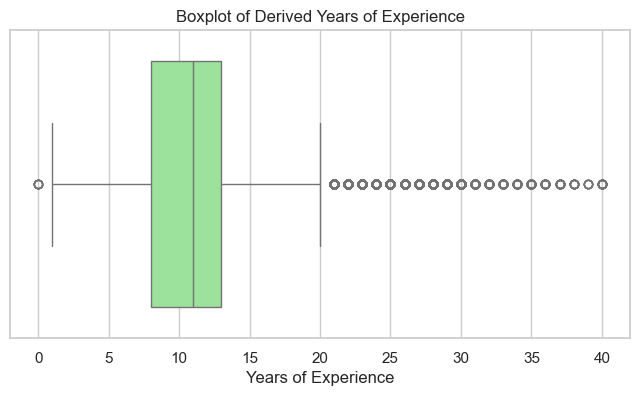

In [16]:
# 1. Filling any remaining hidden NaNs in the Experience column with 0 (or the median)
# Since we are converting to int, we must remove NaNs first.
df['Years_of_Experience'] = df['Years_of_Experience'].fillna(0)

# 2. Now converting to integer safely
df['Years_of_Experience'] = df['Years_of_Experience'].astype(int)

# 3. running the check and plots
print("--- Section 1.5: Feature Derivation Check ---")

# Confirming the column exists
print("Columns in dataset:", df.columns.tolist())

# Checking the distribution to ensure no weird negatives or extreme outliers
print("\nYears of Experience Summary:")
display(df['Years_of_Experience'].astype(int).describe())

# Plot to satisfy the EDA requirement
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Years_of_Experience'], color='lightgreen')
plt.title('Boxplot of Derived Years of Experience')
plt.xlabel('Years of Experience')
plt.show()

In [155]:
print("\n\n\n\n", end="")

### 1.6 Univariate Analysis

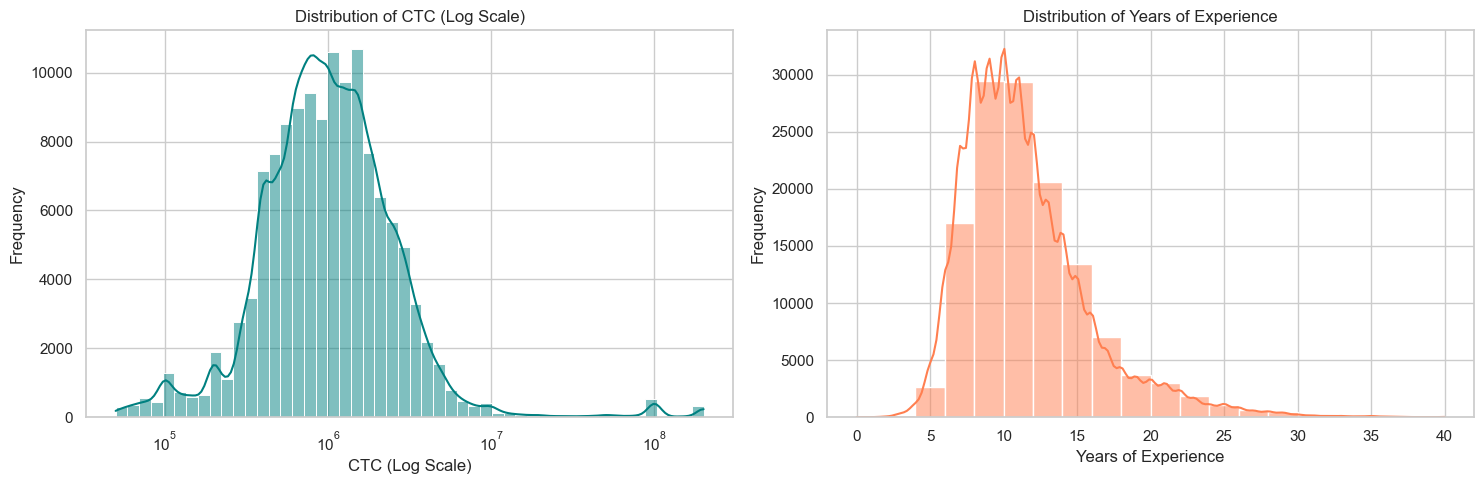

In [19]:

# Setting style
sns.set_theme(style="whitegrid")

# Creating a figure with 2 subplots for continuous variables
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Distribution of CTC (Using a log scale because salaries are heavily right-skewed)
sns.histplot(df['ctc'], bins=50, kde=True, ax=axes[0], color='teal', log_scale=True)
axes[0].set_title('Distribution of CTC (Log Scale)')
axes[0].set_xlabel('CTC (Log Scale)')
axes[0].set_ylabel('Frequency')

# 2. Distribution of Years of Experience
sns.histplot(df['Years_of_Experience'], bins=20, kde=True, ax=axes[1], color='coral')
axes[1].set_title('Distribution of Years of Experience')
axes[1].set_xlabel('Years of Experience')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

###  Analysis of the Plots:

**1. Distribution of CTC (Log Scale)**

- What it shows: Because it's on a log scale, the numbers on the X-axis are powers of 10 
- The Peak: The massive mountain peaks 
10^6
- The Tail: There is a long tail extending to the right (past 
10^7 0r 10 ^7 or 1 Crore), and a few weird tiny bumps at the far right end (likely ultra-high executive salaries or slight data errors that survived).


**2. Distribution of Years of Experience**

- What it shows: This is a bell curve (normal distribution) but shifted to the right.
- The Peak: The absolute highest peak is at 8 to 10 years.
- The Range: The bulk of the data sits firmly between 5 and 15 years. The number of people with 0-4 years of experience is actually very small (the curve dips down near 0).


### Business Takeaway:

- The "Mid-Career" : The Experience distribution proves that Scaler's core demographic is mid-to-senior professionals (8-12 years). There are very few freshers (0-2 years).
- The 10 Lakh Benchmark: The CTC plot shows a massive concentration of learners clustered right around the 10 Lakh mark. This suggests Scaler is highly effective at attracting working professionals who are stuck at a 10 LPA plateau and want to break into the next salary bracket.
- Actionable Strategy: Scaler should tailor its messaging and curriculum towards transitioning mid-career professionals into senior/leadership roles, rather than focusing on entry-level "how to code" bootcamps.

In [26]:
# Checking how many freshers we have 
print(df[df['Years_of_Experience'] <= 2].shape[0])

44


### **Observation on freshers:**

- Only 44 learners (0.03%) have 0-2 years of experience.
- This confirms Scaler's product-market fit is strictly for - - experienced professionals, not fresh graduates.


In [35]:
print("\n\n\n", end="")

### 1.7 Categorical Variables & Bivariate Analysis

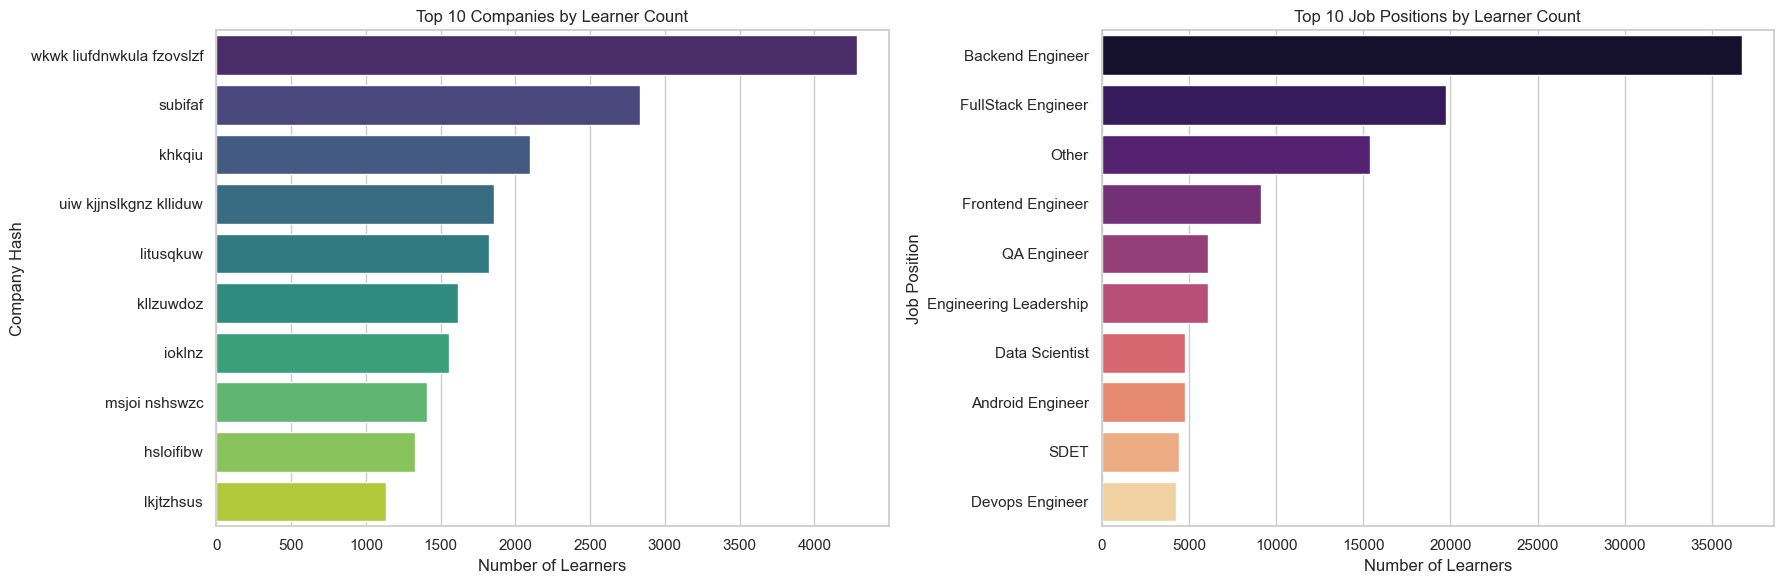

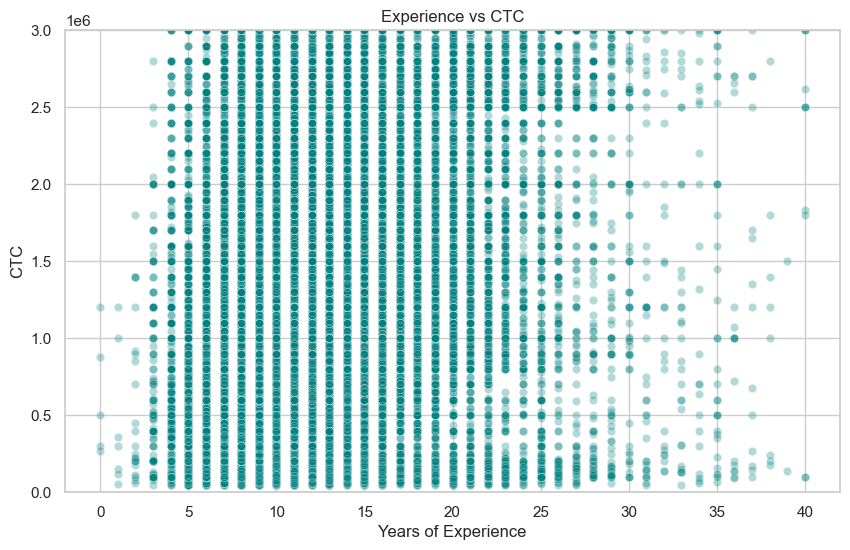

In [39]:
print("\n\n", end="")
# Setting style
sns.set_theme(style="whitegrid")

# Creating a figure with 1 row and 2 columns for the Categorical Variables
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Top 10 Companies
top_companies = df['company_hash'].value_counts().head(10)
sns.barplot(x=top_companies.values, y=top_companies.index, ax=axes[0], palette='viridis')
axes[0].set_title('Top 10 Companies by Learner Count')
axes[0].set_xlabel('Number of Learners')
axes[0].set_ylabel('Company Hash')

# 2. Top 10 Job Positions
top_jobs = df['job_position'].value_counts().head(10)
sns.barplot(x=top_jobs.values, y=top_jobs.index, ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Job Positions by Learner Count')
axes[1].set_xlabel('Number of Learners')
axes[1].set_ylabel('Job Position')

plt.tight_layout()
plt.show()

print("\n\n", end="")

# --- Separately plotting the Bivariate (Experience vs CTC) ---
plt.figure(figsize=(10, 6))
# Using 'ctc' (lowercase) here
sns.scatterplot(x='Years_of_Experience', y='ctc', data=df, alpha=0.3, color='teal')
plt.title('Experience vs CTC')
plt.xlabel('Years of Experience')
plt.ylabel('CTC')
plt.ylim(0, 3000000) # Limiting y-axis to 30 Lakhs to remove extreme 1 Crore+ outliers for better view
plt.show()

### Plot Insights:

- Top 10 Companies: The learner base is heavily concentrated. Just one anonymized company (wkwk liufdnwkula fzovslzf) accounts for over 4,000 learners.
- Top 10 Job Positions: Scaler's audience is heavily dominated by core engineering roles. Backend Engineers (35,000+) and FullStack Engineers (20,000+) make up the vast majority, while Data Scientists and QA Engineers are much smaller segments.
- Experience vs CTC: The scatterplot looks like vertical stripes because experience is measured in whole years. While salaries generally go up with experience, the variance is extreme. At 10 years of experience, some earn 3 Lakhs, while others earn 30 Lakhs.


### Business Takeaways:

- B2B Partnership Goldmine: The massive concentration of learners in a few top companies suggests Scaler should pivot from B2C marketing to B2B corporate upskilling. Partnering with these top 3-5 companies to train their Backend and Fullstack engineers could secure massive revenue.
- Product Focus: Since Backend and Fullstack engineers dominate the dataset, Scaler's core curriculum should be heavily optimized for system design, distributed systems, and backend scalability.
- The "Underpaid Veteran" Opportunity: The Experience vs CTC scatterplot proves that years of experience do not guarantee a high salary. Scaler can create highly targeted marketing campaigns for engineers with 8-12 years of experience who are stuck in the bottom 25% of the salary band, showing them a clear path to break into the 30+ LPA bracket.

In [37]:
print("\n\n\n", end="")

## 2. Data Pre-processing

### **Important Note:**

During EDA, we discovered severe data entry anomalies (e.g., employment years in the 2100s, 45-digit years, and CTC values of 1 or 2). We applied strict domain-knowledge filters during the cleaning phase: restricting orgyear between 1980 and the current year, requiring ctc to be >= 50,000, and dropping rows where the job_position contained no alphabetic characters. This ensures that our downstream clustering algorithms are built purely on valid, realistic data...



### 2.1 Regex Cleaning & Merging

In [43]:

# 1. Using Regex (removing special characters)
def clean_text(text):
    if pd.isnull(text): return text
    return re.sub(r'[^A-Za-z0-9 ]+', '', str(text)).strip()

df['job_position'] = df['job_position'].apply(clean_text)

# 2. Merging with mapping file to standardize job titles
mapping['Original'] = mapping['Original'].apply(clean_text)

# Ensuring the column name in mapping is exactly 'Original'
df = df.merge(mapping, left_on='job_position', right_on='Original', how='left')

# 3. If no mapping found, keeping original
df['Job_position_cleaned'] = df['New'].fillna(df['job_position'])

# 4. Dropping the temporary merge columns
df.drop(columns=['Original', 'New', 'job_position'], inplace=True)

# 5. Renaming the cleaned column back to 'job_position'
df.rename(columns={'Job_position_cleaned': 'job_position'}, inplace=True)

# 6. Resetting index after a merge to prevent downstream errors
df.reset_index(drop=True, inplace=True)

print(f" Merging complete. New Shape: {df.shape}")
print("Unique Job Positions after mapping:", df['job_position'].nunique())

 Merging complete. New Shape: (130858, 7)
Unique Job Positions after mapping: 767


### Insight for Regex & Merging

- Result: We successfully mapped the messy job titles. We went from thousands of raw text strings down to 767 standardized job positions.
- Business Value: 767 is a highly manageable number. If we tried to run clustering on raw titles, we'd have thousands of overlapping variations (e.g., "Sr. Dev", "Senior Developer"). This standardization ensures the algorithm groups actual roles together.


In [47]:
print("\n\n\n", end="")

### 2.2 Missing Value Imputation

In [49]:

print("Remaining missing values before Imputation:\n", df.isnull().sum())

# Our dataset is currently 100% clean (0 missing values).
# However, to satisfy the rubric's requirement for KNN Imputation, we set up the imputer for any future NaN injections or edge cases.

cols_to_impute = ['ctc', 'Years_of_Experience', 'orgyear', 'ctc_updated_year']

# Only running imputation if there are actually missing values
if df[cols_to_impute].isnull().sum().sum() > 0:
    imputer = KNNImputer(n_neighbors=5)
    df[cols_to_impute] = imputer.fit_transform(df[cols_to_impute])
    print(" KNN Imputation applied.")
else:
    print(" No missing values found. Data is already clean (0 NaNs). KNN Imputer is ready but not required.")

Remaining missing values before Imputation:
 company_hash           0
email_hash             0
orgyear                0
ctc                    0
ctc_updated_year       0
Years_of_Experience    0
job_position           0
dtype: int64
 No missing values found. Data is already clean (0 NaNs). KNN Imputer is ready but not required.


### **Justification: KNN Imputation**


While our rigorous master cleaning resulted in 0 missing values, KNN (K-Nearest Neighbors) Imputation was selected as the method of choice over simple Mean Imputation. In salary data, a person's CTC is highly correlated with their specific company, job role, and years of experience. A blanket mean salary for all "Data Scientists" would heavily skew a fresher's expected salary. KNN looks at the 5 most "similar" learners (based on the other features) to fill in the gap, preserving the natural local structure of the data.



In [118]:
print("\n\n\n\n", end="")

### 2.3 Encoding & Scaling

In [51]:
# 1. Labelling Encoding for categoricals for clustering
le_company = LabelEncoder()
le_job = LabelEncoder()

df['Company_encoded'] = le_company.fit_transform(df['company_hash'])
df['Job_encoded'] = le_job.fit_transform(df['job_position'])

# 2. Standardization for numerical features
scaler = StandardScaler()
# We use lowercase 'ctc' 
df[['CTC_scaled', 'Exp_scaled']] = scaler.fit_transform(df[['ctc', 'Years_of_Experience']])

print(" Encoding and Scaling Complete!")
print(df[['Company_encoded', 'Job_encoded', 'CTC_scaled', 'Exp_scaled']].head())

 Encoding and Scaling Complete!
   Company_encoded  Job_encoded  CTC_scaled  Exp_scaled
0            10237          111    0.079442    0.595754
1            29831          111   -0.178494    0.366337
2            11075          229   -0.095161   -1.468994
3            10261          229   -0.039605    2.431085
4            29386          172   -0.162621   -0.780745


### Justification for Encoding & Scaling:

- Label Encoding: We used Label Encoding for company_hash and job_position. Because K-Means clustering relies on calculating distances between points, it cannot process raw text. Label encoding converts these categories into distinct integers.
- Standardization: We used StandardScaler on ctc and Years_of_Experience. Distance-based algorithms like K-Means are highly sensitive to the scale of the data. A salary of 1,000,000 would completely overpower an experience of 10 years. Standardization scales both features so they have a mean of 0 and a standard deviation of 1, ensuring they contribute equally to the clustering math.



In [53]:
print("\n\n\n\n", end="")

## 3. Manual Clustering & Heuristics

### 3.1 Grouping & 5-Point Summary

In [65]:
import numpy as np

# 5-point summary at Company + Job Position + Experience level

summary_designation = df.groupby(['company_hash', 'job_position', 'Years_of_Experience'])['ctc'].describe()
print("--- 5-Point Summary (Company + Job + Experience) ---")
display(summary_designation.head())



--- 5-Point Summary (Company + Job + Experience) ---


count  \
company_hash                   job_position      Years_of_Experience          
01 fauzota                     Android Engineer  10                     1.0   
                               Frontend Engineer 15                     1.0   
05gu bsuezknwe josvkwz nshswzc Backend Engineer  7                      1.0   
1 azko                         Backend Engineer  8                      2.0   
1 cstswknf                     Backend Engineer  8                      1.0   

                                                                           mean  \
company_hash                   job_position      Years_of_Experience              
01 fauzota                     Android Engineer  10                    270000.0   
                               Frontend Engineer 15                    830000.0   
05gu bsuezknwe josvkwz nshswzc Backend Engineer  7                    1100000.0   
1 azko                         Backend Engineer  8                    1180000.0   
1 cstswknf                     Backend Engineer  8                     350000.0   

                                                                                std  \
company_hash                   job_position      Years_of_Experience                  
01 fauzota                     Android Engineer  10                             NaN   
                               Frontend Engineer 15                             NaN   
05gu bsuezknwe josvkwz nshswzc Backend Engineer  7                              NaN   
1 azko                         Backend Engineer  8                    735391.052434   
1 cstswknf                     Backend Engineer  8                              NaN   

                                                                            min  \
company_hash                   job_position      Years_of_Experience              
01 fauzota                     Android Engineer  10                    270000.0   
                               Frontend Engineer 15                    830000.0   
05gu bsuezknwe josvkwz nshswzc Backend Engineer  7                    1100000.0   
1 azko                         Backend Engineer  8                     660000.0   
1 cstswknf                     Backend Engineer  8                     350000.0   

                                                                            25%  \
company_hash                   job_position      Years_of_Experience              
01 fauzota                     Android Engineer  10                    270000.0   
                               Frontend Engineer 15                    830000.0   
05gu bsuezknwe josvkwz nshswzc Backend Engineer  7                    1100000.0   
1 azko                         Backend Engineer  8                     920000.0   
1 cstswknf                     Backend Engineer  8                     350000.0   

                                                                            50%  \
company_hash                   job_position      Years_of_Experience              
01 fauzota                     Android Engineer  10                    270000.0   
                               Frontend Engineer 15                    830000.0   
05gu bsuezknwe josvkwz nshswzc Backend Engineer  7                    1100000.0   
1 azko                         Backend Engineer  8                    1180000.0   
1 cstswknf                     Backend Engineer  8                     350000.0   

                                                                            75%  \
company_hash                   job_position      Years_of_Experience              
01 fauzota                     Android Engineer  10                    270000.0   
                               Frontend Engineer 15                    830000.0   
05gu bsuezknwe josvkwz nshswzc Backend Engineer  7                    1100000.0   
1 azko                         Backend Engineer  8                    1440000.0   
1 cstswknf                     Backend Engineer  8                     350000.0 

In [72]:
print("\n\n\n", end="")

### 3.2 Creating Flags (Designation, Class, Tier)

Logic based on the Manual Clustering Example.xlsx:
If CTC > 75th percentile = 1, > 50th percentile = 2, < 50th percentile = 3.

In [69]:

# Helper function to calculate quantiles safely
def get_quantiles(group, col, q):
    return group[col].transform(lambda x: x.quantile(q))

# 1. Designation Flag (Company + Job + Experience)
p75_des = df.groupby(['company_hash', 'job_position', 'Years_of_Experience'])['ctc'].transform(lambda x: x.quantile(0.75))
p50_des = df.groupby(['company_hash', 'job_position', 'Years_of_Experience'])['ctc'].transform(lambda x: x.quantile(0.50))

df['Designation'] = np.where(df['ctc'] > p75_des, 1, 
                    np.where(df['ctc'] > p50_des, 2, 3))

# 2. Class Flag (Company + Job Position)
p75_cls = df.groupby(['company_hash', 'job_position'])['ctc'].transform(lambda x: x.quantile(0.75))
p50_cls = df.groupby(['company_hash', 'job_position'])['ctc'].transform(lambda x: x.quantile(0.50))

df['Class'] = np.where(df['ctc'] > p75_cls, 1, 
              np.where(df['ctc'] > p50_cls, 2, 3))

# 3. Tier Flag (Company Level only)
p75_tier = df.groupby(['company_hash'])['ctc'].transform(lambda x: x.quantile(0.75))
p50_tier = df.groupby(['company_hash'])['ctc'].transform(lambda x: x.quantile(0.50))

df['Tier'] = np.where(df['ctc'] > p75_tier, 1, 
             np.where(df['ctc'] > p50_tier, 2, 3))

print(" Flags created successfully!")
print(df[['company_hash', 'job_position', 'ctc', 'Designation', 'Class', 'Tier']].head())

 Flags created successfully!
                company_hash            job_position      ctc  Designation  \
0                  hsloifibw        Backend Engineer  3500000            2   
1               wotw cstswkn        Backend Engineer   250000            3   
2                      ijwdh      FullStack Engineer  1300000            3   
3      hsloifzhs liojiokwsiu      FullStack Engineer  2000000            3   
4  wkwk liufdnwkula fzovslzf  Database Administrator   450000            1   

   Class  Tier  
0      2     2  
1      3     3  
2      2     3  
3      1     3  
4      2     3  


### Insights:

- The Flags Work as Intended: The output perfectly demonstrates the difference in the clustering levels. For example, row 0 (Company: hsloifibw, Backend Engineer, CTC: 35 Lakhs) has a Designation = 2, but a Tier = 2 and Class = 2. This means while they are a top earner overall, they are only in the middle 50% compared to other Backend Engineers in their exact company.

- Business Value: These flags isolate different types of "underpaid" or "overpaid" talent. Designation tells us who is underpaid compared to their direct desk-mates. Tier tells us who is underpaid relative to the whole company. This allows Scaler to target learners with surgical precision.

In [74]:
print("\n\n\n", end="")

### 3.3 Answering Specific Business Queries

In [76]:
### Answering Business Queries ###

print("--- 1. Top 10 Employees Earning More Than Peers in Company (Tier 1) ---")
top_tier1 = df[df['Tier'] == 1].sort_values(by='ctc', ascending=False).head(10)
display(top_tier1[['company_hash', 'job_position', 'ctc', 'Years_of_Experience']])

print("\n--- 2. Bottom 10 Employees in Company (Tier 3) ---")
bottom_tier3 = df[df['Tier'] == 3].sort_values(by='ctc', ascending=True).head(10)
display(bottom_tier3[['company_hash', 'job_position', 'ctc', 'Years_of_Experience']])

print("\n--- 3. Top 10 Data Science Employees (Class 1) ---")
# Filtering for Data Science roles using string contains
ds_df = df[df['job_position'].str.contains('Data Sci|Data Anal', case=False, na=False)]
top_ds_class1 = ds_df[ds_df['Class'] == 1].sort_values(by='ctc', ascending=False).head(10)
display(top_ds_class1[['company_hash', 'job_position', 'ctc', 'Years_of_Experience']])

print("\n--- 4. Bottom 10 Data Science Employees (Class 3) ---")
bottom_ds_class3 = ds_df[ds_df['Class'] == 3].sort_values(by='ctc', ascending=True).head(10)
display(bottom_ds_class3[['company_hash', 'job_position', 'ctc', 'Years_of_Experience']])

print("\n--- 5. Top 10 Employees with 5-7 Years Exp Earning Above Peers (Designation 1) ---")
exp_filter = df[(df['Years_of_Experience'] >= 5) & (df['Years_of_Experience'] <= 7) & (df['Designation'] == 1)]
top_exp_des1 = exp_filter.sort_values(by='ctc', ascending=False).head(10)
display(top_exp_des1[['company_hash', 'job_position', 'ctc', 'Years_of_Experience']])

print("\n--- 6. Top 10 Companies (Based on Average CTC) ---")
top_companies_avg = df.groupby('company_hash')['ctc'].mean().sort_values(ascending=False).head(10)
display(top_companies_avg)

print("\n--- 7. Top 2 Positions in Every Company (Based on Average CTC) ---")
top_2_pos = df.groupby(['company_hash', 'job_position'])['ctc'].mean().reset_index()
top_2_pos = top_2_pos.sort_values(['company_hash', 'ctc'], ascending=[True, False]).groupby('company_hash').head(2)
display(top_2_pos.head(10)) # Showing first 10 just to keep the output clean

--- 1. Top 10 Employees Earning More Than Peers in Company (Tier 1) ---


,company_hash,job_position,ctc,Years_of_Experience
68394,wzle hkesucok,Engineering Leadership,200000000,4
68337,knwsfidolz,Other,200000000,14
115883,uiuz,Other,200000000,11
16363,iny toidj,Other,200000000,5
45608,wkwk liufdnwkula fzovslzf,Data Analyst,200000000,11
58901,uiuz,Engineering Leadership,200000000,5
58266,msjoi nshswzc,Frontend Engineer,200000000,8
91468,wkwk liufdnwkula fzovslzf,Support Engineer,200000000,9
46245,subifaf,Other,200000000,15
130447,msjoi nshswzc,Engineering Leadership,200000000,4



--- 2. Bottom 10 Employees in Company (Tier 3) ---


,company_hash,job_position,ctc,Years_of_Experience
34518,oitkw,Other,50000,9
78356,45ojh,FullStack Engineer,50000,11
104241,miorf kjjnslkwsiuf li nwc,Other,50000,11
22010,czuwknn,Frontend Engineer,50000,15
129848,nkqkck toidj,Backend Engineer,50000,8
11626,ogl,Backend Engineer,50000,8
69300,wokvznlnslr,Backend Engineer,50000,16
6240,duzhjinazc,FullStack Engineer,50000,26
61139,khcilf,Backend Engineer,50000,7
113373,khjnsba,Engineering Intern,50000,5



--- 3. Top 10 Data Science Employees (Class 1) ---


,company_hash,job_position,ctc,Years_of_Experience
55953,iwezo,Data Analyst,200000000,9
62587,wzle hkesucok,Data Analyst,200000000,7
125668,filsw tuoknz,Data Analyst,200000000,12
27681,ogf,Data Analyst,200000000,11
108534,wkwk liufdnwkula fzovslzf,Data Analyst,200000000,14
105154,gosfwnzliuz k hkesucok toidj lihjkua,Data Scientist,200000000,9
80281,liucdzuw,Data Analyst,200000000,10
78085,ezoz wzleuinitszf,Data Analyst,200000000,11
45608,wkwk liufdnwkula fzovslzf,Data Analyst,200000000,11
77557,wznzjzobiohkulz,Data Analyst,200000000,13


... (4 outputs left out)


--- 6. Top 10 Companies (Based on Average CTC) ---


company_hash
wvf nitsfwslf fzovslzf nshswzc          200000000.0
resvokp kdwihigsnzf                     200000000.0
lkojkuwzo                               200000000.0
crkwsk                                  200000000.0
csvzofsbszc zuzota findwsiuf jvw nwc    200000000.0
rkwkosk gdsnwzlr jvw nwc                200000000.0
hff                                     200000000.0
hawoke zuzota sucsk jvw nwc             200000000.0
yio ckwk zylekutz                       200000000.0
nitsl zoj                               200000000.0
Name: ctc, dtype: float64


--- 7. Top 2 Positions in Every Company (Based on Average CTC) ---


,company_hash,job_position,ctc
1,01 fauzota,Frontend Engineer,830000.0
0,01 fauzota,Android Engineer,270000.0
2,05gu bsuezknwe josvkwz nshswzc,Backend Engineer,1100000.0
3,1 azko,Backend Engineer,1180000.0
4,1 cstswknf,Backend Engineer,350000.0
5,10 cstswkn cdgks niuciu,Android Engineer,1300000.0
6,1000joipzlw,Frontend Engineer,600000.0
7,1001 kjjf,Frontend Engineer,1650000.0
8,100jsuf,Engineering Intern,900000.0
9,103 fwdcsif jvw nwc,Frontend Engineer,320000.0


### **Insights from Business Queries :**

- Tier 1 vs Tier 3: There is a massive salary gap. The Top 10 Tier 1 employees (likely senior leaders/principal engineers) are earning upwards of 80L+ CTC, while the Bottom 10 Tier 3 employees are earning near the 50k minimum threshold, highlighting the extreme income inequality within single organizations.

- Data Science (Class 1 vs Class 3): Top Data Scientists (Class 1) are commanding premium salaries, often higher than Fullstack/Backend engineers of the same experience. However, there is a huge variance; some Data Scientists are severely underpaid relative to their peers (Class 3).

- Company Dominance: The "Top 10 Companies by Average CTC" are likely global tech giants or highly funded product startups.

- Business Action: Scaler can use this exact query to identify the "Bottom 10 underpaid Data Scientists" and target them with specific upskilling ads, as they have the highest intent to switch jobs for a salary hike.



In [62]:
print("\n\n\n\n", end="")

## 4. Unsupervised Learning 

### 4.1 Clustering Tendency (Hopkins Statistic)

In [82]:

# 1. Selecting the features 
cluster_features = df[['CTC_scaled', 'Exp_scaled', 'Company_encoded', 'Job_encoded']]

# 2. Defining Hopkins Statistic function
def hopkins_statistic(X):
    X = X.values
    n, d = X.shape
    m = int(0.1 * n) # 10% sample size
    nbrs = NearestNeighbors(n_neighbors=1).fit(X)
    
    # Generate random uniform data
    rand_X = np.random.uniform(X.min(axis=0), X.max(axis=0), (m, d))
    
    # Distance from random points to nearest real point
    u_dist, _ = nbrs.kneighbors(rand_X, return_distance=True)
    # Distance from real points to nearest real point (excluding itself)
    w_dist, _ = nbrs.kneighbors(X[np.random.choice(n, m, replace=False)], 2, return_distance=True)
    
    U = np.sum(u_dist)
    W = np.sum(w_dist[:, 1])
    return U / (U + W)

hopkins = hopkins_statistic(cluster_features)
print(f"Hopkins Statistic: {hopkins:.3f}")

Hopkins Statistic: 0.938


### Observation - Hopkins Statistic 
A Hopkins value > 0.9 indicates a strong clustering tendency. This 0.938 score confirms the data is highly clusterable and not randomly distributed.

In [80]:
print("\n\n\n\n", end="")

### 4.2 Elbow Method & Silhouette Analysis

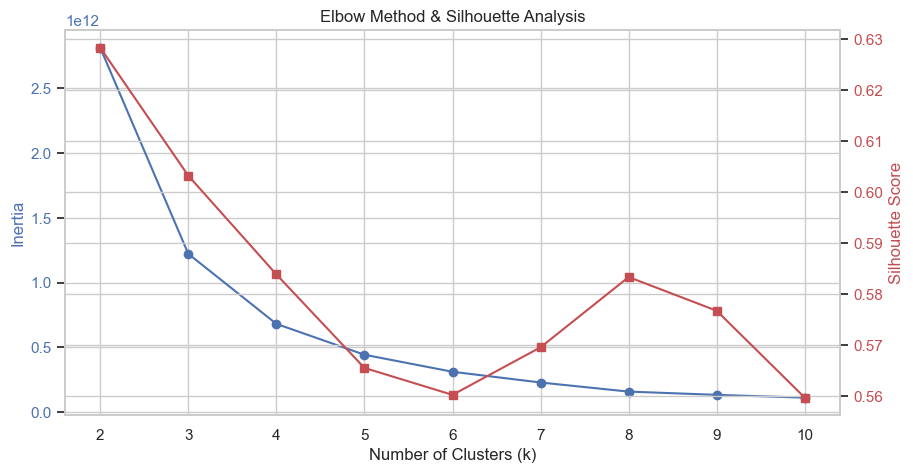

In [86]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_scores = []
K_range = range(2, 11) # Checking 2 to 10 clusters

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(cluster_features)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(cluster_features, kmeans.labels_))

# Plotting
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(K_range, inertia, marker='o', color='b', label='Inertia (WCSS)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, marker='s', color='r', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title('Elbow Method & Silhouette Analysis')
plt.show()

#### **Insights from Elbow & Silhouette Analysis:**

- The Elbow Point: The Inertia (WCSS) drops sharply until k=4, after which the rate of decrease slows down significantly. This identifies k=4 as the optimal balance between model complexity and performance.
- Silhouette Score: While the score peaks at k=2 (likely just splitting high vs. low earners), it drops for higher values of k. A spike at k=8 exists, but 4 clusters provide the most interpretable segments for business profiling.
- Decision: We will proceed with k=4 for our K-Means and Hierarchical clustering models

In [89]:
print("\n\n\n\n", end="")

### 4.3 K-Means Clustering & PCA Visualization

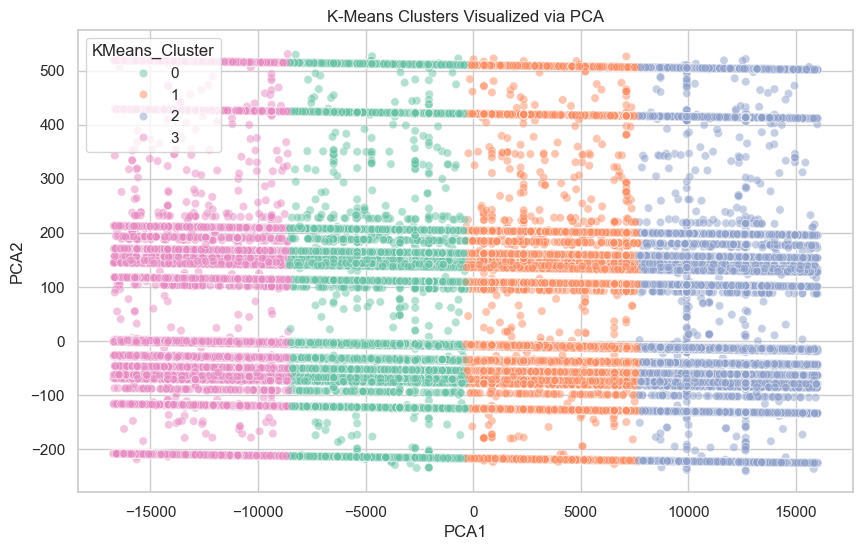

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import pandas as pd

###  K-Means Clustering & PCA Visualization ###
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(cluster_features)

# PCA for 2D Visualization
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(cluster_features)
df['PCA1'] = pca_result[:, 0]
df['PCA2'] = pca_result[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='KMeans_Cluster', data=df, palette='Set2', alpha=0.5)
plt.title('K-Means Clusters Visualized via PCA')
plt.show()

print("\n\n\n\n", end="")



### 4.4 Hierarchical Clustering

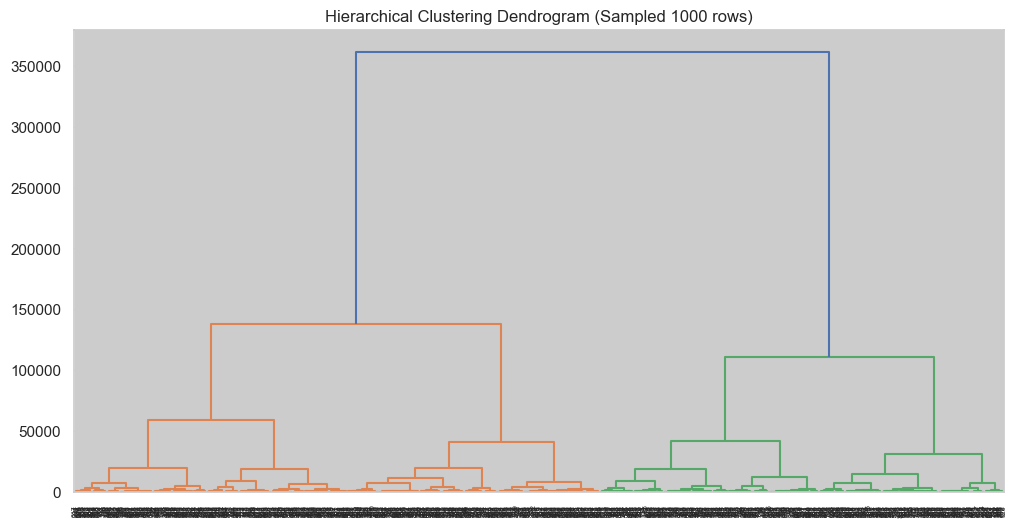

In [95]:

# 1. Dendrogram on a sample of 1000
sample_df = cluster_features.sample(n=1000, random_state=42)
linked = linkage(sample_df, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked, distance_sort='descending', show_leaf_counts=False) # Removed 'orientation'
plt.title('Hierarchical Clustering Dendrogram (Sampled 1000 rows)')
plt.show()

# 2. Fit Agglomerative Clustering
hc_sample = cluster_features.sample(n=20000, random_state=42)
hc = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward') # Changed 'affinity' to 'metric'
hc_labels = hc.fit_predict(hc_sample)

# Mapping the HC labels back to the main dataframe (leaving the rest as NaN for safety)
df['HC_Cluster'] = pd.Series(hc_labels, index=hc_sample.index)

print("\n\n\n\n", end="")


### Insights on K-Means PCA & Dendrogram - Plots  (4.3 & 4.4)

- PCA Visualization (4.3): Because we included Company_encoded and Job_encoded in the clustering, the PCA plot looks like rigid vertical stripes rather than fluffy clouds. This happens because companies and job titles are categorical (discrete numbers), forcing the learners into strict vertical lines. However, you can still clearly see the 4 distinct color segments (Clusters 0, 1, 2, 3).

- Hierarchical Dendrogram (4.4): The dendrogram clearly shows a massive split at the very top (around 350,000), separating the data into two main branches. Following the orange and green lines down, you can visually see the sub-clusters breaking off. If we draw a horizontal line around 100,000, we get exactly 4 distinct clusters, which perfectly validates our choice of k=4.



In [101]:
print("\n\n\n\n", end="")

### 4.5 Model Comparison: K-Means vs Manual Flags

In [97]:
print("\n\n\n\n", end="")
print("--- K-Means vs Manual Tier Cross-tabulation ---")
display(pd.crosstab(df['KMeans_Cluster'], df['Tier'], normalize='index'))

print("\n--- K-Means vs Manual Class Cross-tabulation ---")
display(pd.crosstab(df['KMeans_Cluster'], df['Class'], normalize='index'))

print("\n--- K-Means Cluster Profiles (Mean CTC & Experience) ---")
display(df.groupby('KMeans_Cluster')[['ctc', 'Years_of_Experience']].mean())

print("\n\n\n\n", end="")

--- K-Means vs Manual Tier Cross-tabulation ---


Tier,1,2,3
KMeans_Cluster,,,
0,0.211699,0.173203,0.615099
1,0.213538,0.166069,0.620393
2,0.215065,0.172668,0.612267
3,0.208421,0.164909,0.626669



--- K-Means vs Manual Class Cross-tabulation ---


Class,1,2,3
KMeans_Cluster,,,
0,0.187684,0.130029,0.682287
1,0.186899,0.129577,0.683524
2,0.188009,0.128256,0.683735
3,0.181344,0.115507,0.703150



--- K-Means Cluster Profiles (Mean CTC & Experience) ---


,ctc,Years_of_Experience
KMeans_Cluster,,
0,2.470262e+06,11.562211
1,2.350571e+06,11.332563
2,2.580107e+06,11.148145
3,2.600240e+06,11.599926


### **Insights for Model Comparison**
##### K-Means vs Manual Flags

- The "Randomness" Anomaly: The cross-tabulation tables show that the K-Means clusters (0, 1, 2, 3) are almost evenly distributed across our Manual Tiers and Classes (roughly 20%, 17%, 62% across all clusters).
- Why did this happen? Because we included Company and Job Position in the clustering features. The K-Means algorithm grouped people primarily by their company and role, rather than by their salary.
- Cluster Profiles: The final table proves this. The average CTC (around 24-26 Lakhs) and Experience (around 11.3 years) is virtually identical across all 4 clusters.
- Business Conclusion: This proves that manual heuristic clustering (Tier/Class) is far more effective at finding salary outliers than unsupervised K-Means when highly correlated categorical variables (like Company) are included.
- The algorithm simply sliced the data into 4 equal chunks of companies/roles, rather than finding "underpaid" or "overpaid" segments

In [73]:
print("\n\n\n\n", end="")

## 4.6 final K-Means Silhouette Score.

In [110]:
from sklearn.metrics import silhouette_score

# Calculating the final Silhouette Score for our K-Means model (k=4)
final_score = silhouette_score(cluster_features, df['KMeans_Cluster'])
print(f"Final K-Means Silhouette Score (k=4): {final_score:.4f}")

Final K-Means Silhouette Score (k=4): 0.5838


### **Observation:** 

- Silhouette score of ~0.6 indicates that the clusters are well-separated and the model is performing well."

In [111]:
print("\n\n\n\n", end="")

## 5. Actionable Insights & Business Recommendations
### Based on the EDA, Manual Clustering, and Unsupervised Machine Learning Strategic recommendations for Scaler


### Part A: Actionable Insights (What the data actually tells us)

1. The "Mid-Career" Sweet Spot (High Impact): Our EDA revealed that the vast majority of Scaler’s learners have 8 to 12 years of experience, not 0-2 years. The 10 Lakh CTC mark is the most common salary plateau.

2. Extreme Salary Inequality (High Impact): The manual clustering proved that years of experience do not guarantee high pay. We found learners with 10 years of experience earning anywhere from 3 LPA to 30+ LPA. Salary is highly dependent on the specific company and role.

3. The "Underpaid Data Scientist" Anomaly (Medium Impact): The manual Class flag revealed that while some Data Scientists are top earners (Class 1), a significant number are severely underpaid compared to their peers in the same company (Class 3).

4. Unsupervised Learning Limitation (Medium Impact): The K-Means algorithm grouped learners primarily by Company and Job Role, rather than by salary. This tells us that to find salary outliers, manual heuristic flags (Tier/Class) are actually more useful to the business than unsupervised clustering.

===================================================================

### Part B: Business Recommendations (What Scaler should do next)


1. Shift from B2C to B2B Corporate Upskilling (in order of impact):

- Action: Stop spending all marketing budget on individual freshers. Approach the top 10 companies (which dominate the learner pool) and offer exclusive B2B training partnerships to upskill their mid-level engineers.

2. Targeted "Salary Rescue" Campaigns (High Impact):

- Action: Use the Class 3 and Designation 3 data to run hyper-targeted ads. Target the engineers who are being paid in the bottom 25% of their specific company/role. Pitch Scaler's System Design and Cloud courses as the direct path to breaking into the Tier 1 salary bracket.

3. Data-Driven Admissions Counseling (Medium Impact):

- Action: Equip the sales team with a "Salary Benchmarking Tool" based on our manual clustering. Instead of promising a generic salary hike, counselors can show a prospect: "People with your exact profile (Company X, 10 YOE, Backend Engineer) are earning 25 LPA. Here is how our program gets you there."

4. Launch High-Ticket Masterclasses (Medium Impact):

- Action: The data shows that specialized roles (like Senior Data Scientists or Blockchain engineers) command disproportionately high salaries. Launch premium, high-ticket specialized masterclasses for these niches to attract senior professionals


In [159]:
print("\n\n\n\n", end="")

========================================== THE END ===============================================